# Rakuten Product Classification — Visualizations 3+

This notebook contains the **visualizations from the newer audit notebook starting with Figure 3**, but adapted so it can run inside the existing `liora-capstone` GitHub project.

The data is loaded at the beginning using the project's existing helper:

```python
df = load_merged_data()
```

Figures 1 and 2 from the newer notebook are intentionally omitted.


## 1. Imports

In [2]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import Markdown, display

from src.data_utils import load_merged_data, load_image

RANDOM_STATE = 42

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (12, 6),
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PALETTE = {
    "primary": "#BF0000",
    "secondary": "#7A0019",
    "accent": "#E3A008",
    "neutral": "#64748B",
    "light": "#E2E8F0",
}

print("Environment loaded successfully.")


Environment loaded successfully.


## 2. Load Data

In [3]:
df = load_merged_data()

print("Dataset shape:", df.shape)
display(df.head(5))


Dataset shape: (84916, 5)


,designation,description,productid,imageid,prdtypecode
0,Olivia: Personalisiertes Notizbuch / 150 Seiten / Punktraster / Ca Din A5 / Rosen-Design,NaN,3804725264,1263597046,10
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L'art Et Son Marche Salon D'art Asiatique A Paris - Jacques Barrere - F...,NaN,436067568,1008141237,2280
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo Wii U - Speedlink Pilot Style,PILOT STYLE Touch Pen de marque Speedlink est 1 stylet ergonomique pour GamePad Nintendo Wii U.<br> Pour un confort ...,201115110,938777978,50
3,Peluche Donald - Europe - Disneyland 2000 (Marionnette À Doigt),NaN,50418756,457047496,1280
4,La Guerre Des Tuques,Luc a des id&eacute;es de grandeur. Il veut organiser un jeu de guerre de boules de neige et s'arranger pour en &eci...,278535884,1077757786,2705


## 3. Audit Feature Construction

The following analytical features are required by Figures 3 onward.  
The original dataframe `df` remains unchanged.


In [4]:
def feature_frame(data: pd.DataFrame) -> pd.DataFrame:
    result = data.copy()

    designation = result["designation"].fillna("").astype(str)
    description = result["description"].fillna("").astype(str)

    result["has_description"] = (
        result["description"].notna()
        & description.str.strip().ne("")
    )

    result["designation_chars"] = designation.str.len()
    result["designation_words"] = designation.str.findall(r"\b\w+\b").str.len()

    result["description_chars"] = description.str.len()
    result["description_words"] = description.str.findall(r"\b\w+\b").str.len()

    result["total_text_chars"] = (
        result["designation_chars"]
        + result["description_chars"]
    )

    normalized = (
        designation
        .str.normalize("NFKD")
        .str.encode("ascii", errors="ignore")
        .str.decode("ascii")
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace(r"[^a-z0-9 ]", "", regex=True)
        .str.strip()
    )

    result["designation_normalized"] = normalized

    result["contains_html"] = description.str.contains(
        r"<[^>]+>",
        regex=True,
        na=False,
    )

    result["contains_url"] = (
        designation + " " + description
    ).str.contains(
        r"https?://|www\.",
        regex=True,
        case=False,
        na=False,
    )

    result["contains_mojibake"] = (
        designation + " " + description
    ).str.contains(
        r"Ã.|Â.|â€|�",
        regex=True,
        na=False,
    )

    return result


train_audit = feature_frame(df)

display(
    train_audit[
        [
            "designation",
            "has_description",
            "designation_chars",
            "description_chars",
            "total_text_chars",
        ]
    ].head()
)


,designation,has_description,designation_chars,description_chars,total_text_chars
0,Olivia: Personalisiertes Notizbuch / 150 Seiten / Punktraster / Ca Din A5 / Rosen-Design,False,88,0,88
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L'art Et Son Marche Salon D'art Asiatique A Paris - Jacques Barrere - F...,False,206,0,206
2,Grand Stylet Ergonomique Bleu Gamepad Nintendo Wii U - Speedlink Pilot Style,True,76,760,836
3,Peluche Donald - Europe - Disneyland 2000 (Marionnette À Doigt),False,63,0,63
4,La Guerre Des Tuques,True,20,213,233


In [5]:
def insight(
    title: str,
    observation: str,
    validation: str,
    business: str,
) -> None:
    display(
        Markdown(
            f"### {title}\n\n"
            f"**Observation.** {observation}\n\n"
            f"**Quantitative validation.** {validation}\n\n"
            f"**Business implication.** {business}"
        )
    )


def cramers_v(contingency: pd.DataFrame) -> float:
    chi2 = stats.chi2_contingency(
        contingency,
        correction=False,
    )[0]

    n = contingency.to_numpy().sum()
    rows, columns = contingency.shape

    phi2 = chi2 / n

    phi2_corrected = max(
        0,
        phi2
        - ((columns - 1) * (rows - 1))
        / max(n - 1, 1),
    )

    rows_corrected = (
        rows
        - ((rows - 1) ** 2)
        / max(n - 1, 1)
    )

    columns_corrected = (
        columns
        - ((columns - 1) ** 2)
        / max(n - 1, 1)
    )

    denominator = min(
        columns_corrected - 1,
        rows_corrected - 1,
    )

    return (
        math.sqrt(phi2_corrected / denominator)
        if denominator > 0
        else 0.0
    )


## 4. Figure 3 — Description Availability by Class

If missing descriptions are associated with the target, description availability itself may contain category-related information.


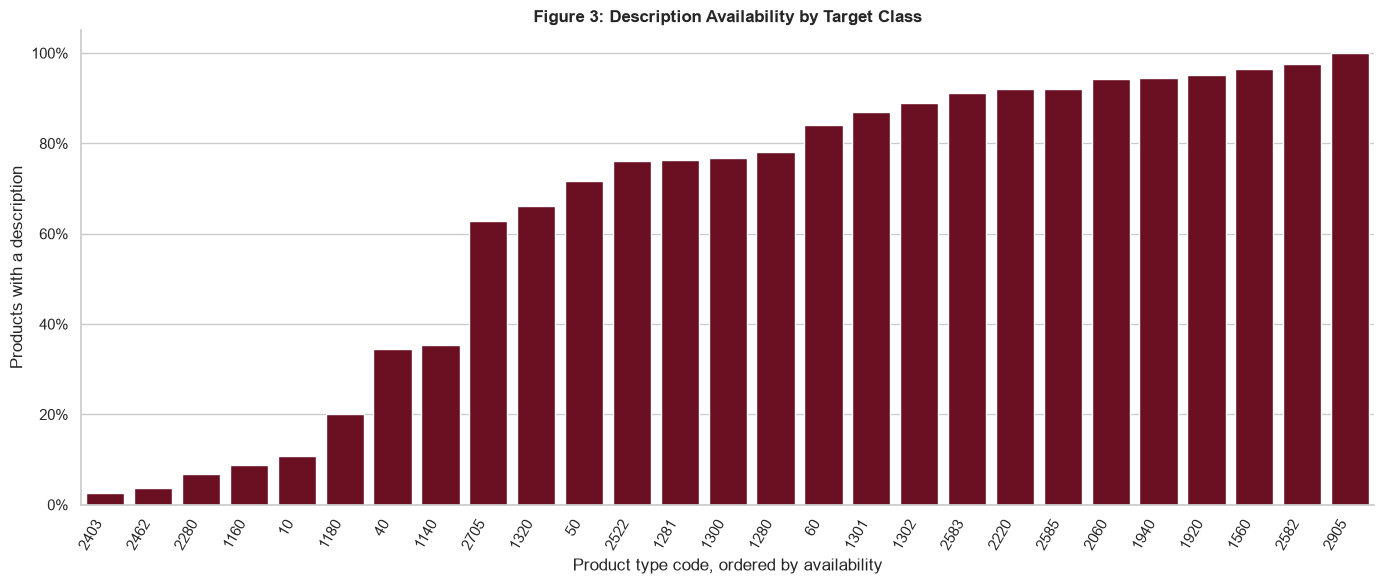

In [6]:
description_by_class = (
    train_audit
    .groupby("prdtypecode", as_index=False)
    .agg(
        products=("has_description", "size"),
        description_available=("has_description", "mean"),
    )
    .sort_values("description_available")
)

plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=description_by_class,
    x="prdtypecode",
    y="description_available",
    order=description_by_class["prdtypecode"],
    color=PALETTE["secondary"],
)

ax.set_title(
    "Figure 3: Description Availability by Target Class"
)
ax.set_xlabel(
    "Product type code, ordered by availability"
)
ax.set_ylabel(
    "Products with a description"
)
ax.yaxis.set_major_formatter(
    lambda value, _: f"{value:.0%}"
)

plt.xticks(
    rotation=60,
    ha="right",
)
plt.tight_layout()
plt.show()


In [7]:
description_class_table = pd.crosstab(
    train_audit["prdtypecode"],
    train_audit["has_description"],
)

chi2, p_value, _, _ = stats.chi2_contingency(
    description_class_table
)

v_description_class = cramers_v(
    description_class_table
)

availability_range = (
    description_by_class["description_available"].min(),
    description_by_class["description_available"].max(),
)

insight(
    "Finding 3 — missing descriptions are category-dependent",
    (
        f"Class-level description availability ranges from "
        f"{availability_range[0]:.1%} to "
        f"{availability_range[1]:.1%}."
    ),
    (
        f"χ²={chi2:,.1f}, "
        f"p={p_value:.3g}, "
        f"Cramér's V={v_description_class:.3f}."
    ),
    (
        "Description presence may improve classification, "
        "but it can also reflect seller behaviour rather than product semantics."
    ),
)


### Finding 3 — missing descriptions are category-dependent

**Observation.** Class-level description availability ranges from 2.6% to 100.0%.

**Quantitative validation.** χ²=43,757.8, p=0, Cramér's V=0.718.

**Business implication.** Description presence may improve classification, but it can also reflect seller behaviour rather than product semantics.

## 5. Figure 4 — Designation Length by Class

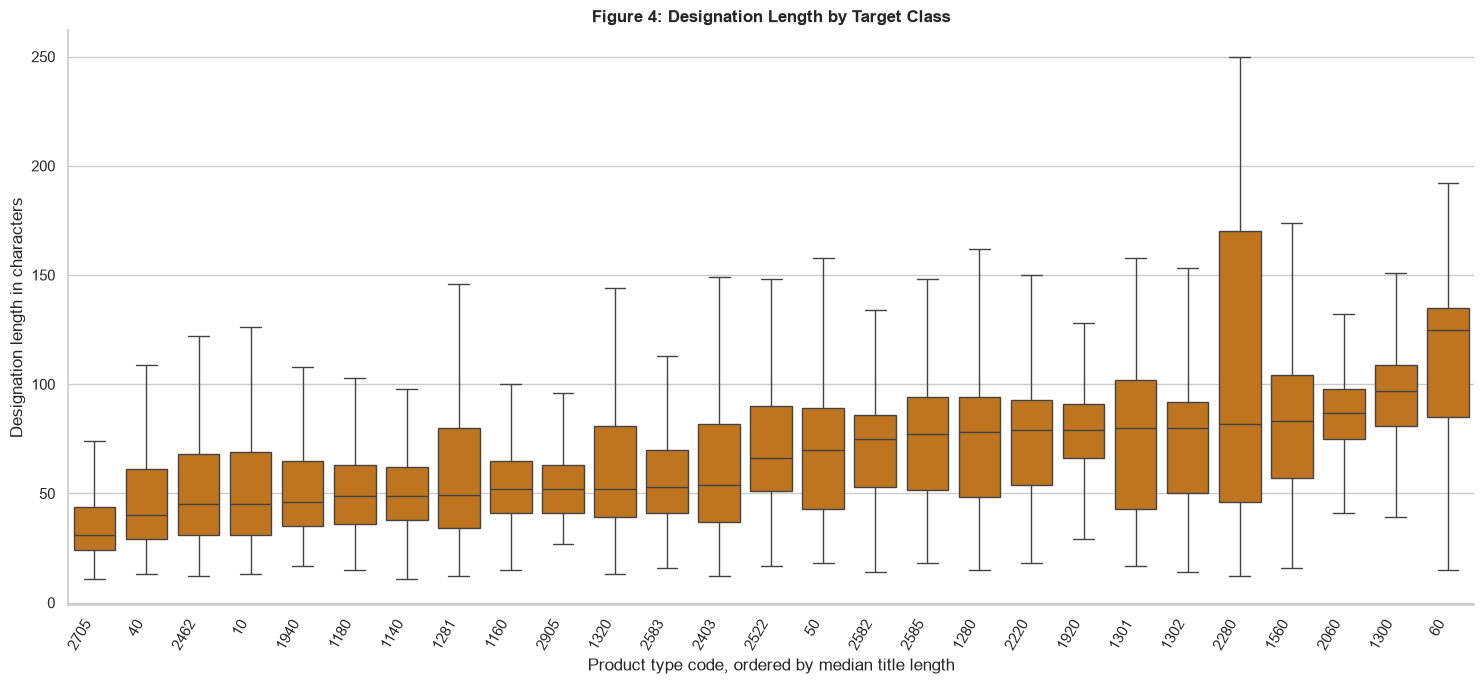

In [28]:
class_order = (
    train_audit
    .groupby("prdtypecode")["designation_chars"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(15, 7))

ax = sns.boxplot(
    data=train_audit,
    x="prdtypecode",
    y="designation_chars",
    order=class_order,
    color="#D97706",
    showfliers=False,
)

ax.set_title(
    "Figure 4: Designation Length by Target Class"
)

ax.set_xlabel(
    "Product type code, ordered by median title length"
)

ax.set_ylabel(
    "Designation length in characters"
)

plt.xticks(
    rotation=60,
    ha="right"
)

plt.tight_layout()
plt.show()



In [ ]:
groups = [
    group["designation_chars"].to_numpy()
    for _, group
    in train_audit.groupby(
        "prdtypecode",
        sort=False,
    )
]

h_stat, p_value = stats.kruskal(
    *groups
)

n = len(train_audit)
k = len(groups)

epsilon_squared = max(
    0.0,
    (h_stat - k + 1)
    / (n - k),
)

median_range = (
    train_audit
    .groupby("prdtypecode")["designation_chars"]
    .median()
    .agg(["min", "max"])
)

insight(
    "Finding 4 — title length contains target-related structure",
    (
        f"Median designation length by class ranges "
        f"from {median_range['min']:.0f} to "
        f"{median_range['max']:.0f} characters."
    ),
    (
        f"Kruskal–Wallis H={h_stat:,.1f}, "
        f"p={p_value:.3g}; "
        f"epsilon-squared={epsilon_squared:.3f}."
    ),
    (
        "Text models should consider both word and character information. "
        "For neural models, sequence length should be chosen from the observed distribution."
    ),
)


## 6. Figure 5 — Relationship Between Designation and Description Length

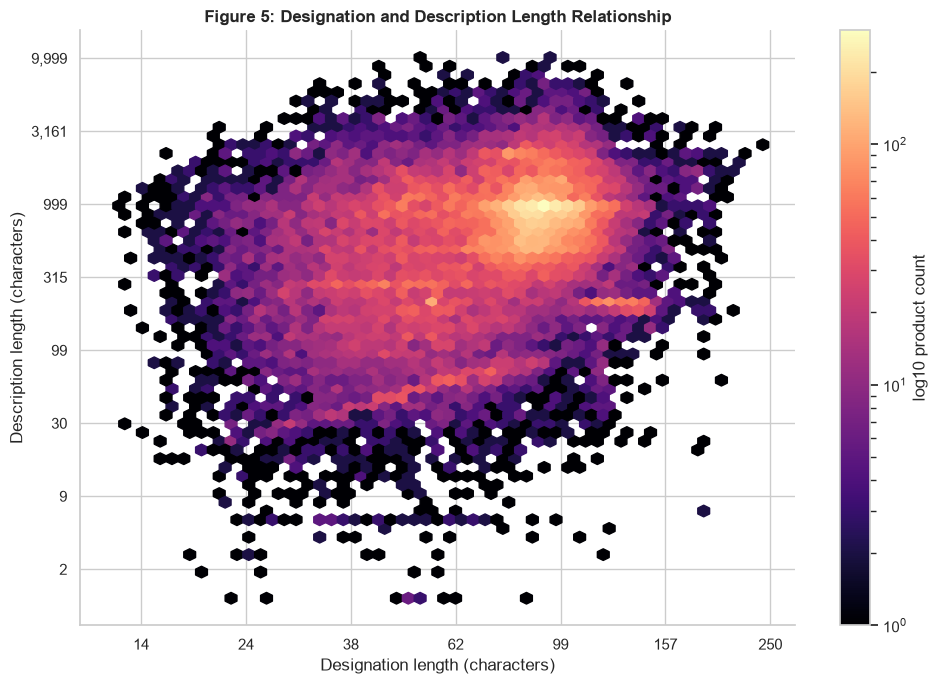

In [25]:
with_description = train_audit.loc[
    train_audit["has_description"],
    [
        "designation_chars",
        "description_chars",
    ],
].copy()

plot_sample = with_description.sample(
    min(
        30_000,
        len(with_description),
    ),
    random_state=RANDOM_STATE,
)

plot_sample = plot_sample.assign(
    designation_log=np.log10(
        1 + plot_sample["designation_chars"]
    ),
    description_log=np.log10(
        1 + plot_sample["description_chars"]
    ),
)

plt.figure(figsize=(10, 7))

hexbin = plt.hexbin(
    plot_sample["designation_log"],
    plot_sample["description_log"],
    gridsize=55,
    mincnt=1,
    bins="log",
    cmap="magma",
)

plt.colorbar(
    hexbin,
    label="log10 product count",
)

from matplotlib.ticker import FuncFormatter

plt.title(
    "Figure 5: Designation and Description Length Relationship"
)

plt.xlabel("Designation length (characters)")
plt.ylabel("Description length (characters)")

# Convert log10(1 + chars) back to character counts for axis labels
formatter = FuncFormatter(
    lambda x, _: f"{int(10**x - 1):,}"
)

plt.gca().xaxis.set_major_formatter(formatter)
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()



“Descriptions are much longer than designations, while their lengths are only moderately correlated. Therefore, we should test whether combining both text fields improves classification.”

## 8. Figure 7 — Duplicate Designations and Conflicting Labels

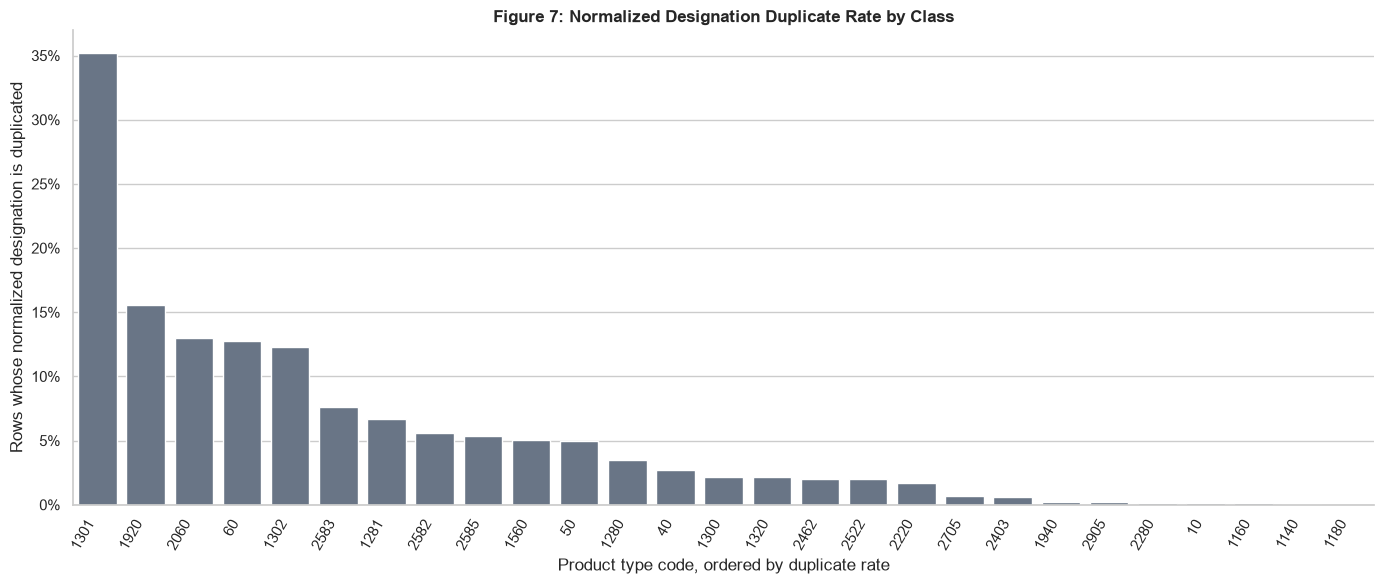

In [12]:
title_stats = (
    train_audit
    .groupby(
        "designation_normalized",
        dropna=False,
    )
    .agg(
        rows=(
            "designation_normalized",
            "size",
        ),
        classes=(
            "prdtypecode",
            "nunique",
        ),
    )
)

duplicate_titles = (
    title_stats.loc[
        title_stats["rows"] > 1
    ]
)

duplicate_rows = int(
    duplicate_titles["rows"]
    .sum()
)

conflicting_groups = (
    duplicate_titles.loc[
        duplicate_titles["classes"] > 1
    ]
)

conflicting_rows = int(
    conflicting_groups["rows"]
    .sum()
)

duplicate_by_class = (
    train_audit
    .assign(
        is_duplicate=
        train_audit[
            "designation_normalized"
        ].duplicated(
            keep=False
        )
    )
    .groupby(
        "prdtypecode",
        as_index=False,
    )
    .agg(
        products=(
            "prdtypecode",
            "size",
        ),
        duplicate_rate=(
            "is_duplicate",
            "mean",
        ),
    )
    .sort_values(
        "duplicate_rate",
        ascending=False,
    )
)

plt.figure(figsize=(14, 6))

ax = sns.barplot(
    data=duplicate_by_class,
    x="prdtypecode",
    y="duplicate_rate",
    order=duplicate_by_class[
        "prdtypecode"
    ],
    color=PALETTE["neutral"],
)

ax.set_title(
    "Figure 7: Normalized Designation Duplicate Rate by Class"
)
ax.set_xlabel(
    "Product type code, ordered by duplicate rate"
)
ax.set_ylabel(
    "Rows whose normalized designation is duplicated"
)

ax.yaxis.set_major_formatter(
    lambda value, _: f"{value:.0%}"
)

plt.xticks(
    rotation=60,
    ha="right",
)
plt.tight_layout()
plt.show()


In [17]:
insight(
    "Finding 7 — duplicates create a validation-leakage risk",
    (
        f"{duplicate_rows:,} training rows "
        f"({duplicate_rows / len(train_audit):.1%}) "
        f"belong to a repeated normalized designation. "
        f"{conflicting_rows:,} rows belong to duplicate-title groups "

        f"containing more than one target class."
    ),
    (
        f"There are {len(duplicate_titles):,} repeated-title groups and "
        f"{len(conflicting_groups):,} conflicting-label groups."
    ),
    (
        "Compare a standard stratified split with a grouped split based on "
        "normalized designation. Review conflicting groups before modeling."
    ),
)


### Finding 7 — duplicates create a validation-leakage risk

**Observation.** 4,172 training rows (4.9%) belong to a repeated normalized designation. 497 rows belong to duplicate-title groups containing more than one target class.

**Quantitative validation.** There are 1,463 repeated-title groups and 160 conflicting-label groups.

**Business implication.** Compare a standard stratified split with a grouped split based on normalized designation. Review conflicting groups before modeling.

4.172 Zeilen = 4,9 % des gesamten Trainingsdatensatzes haben einen normalisierten Titel, der mindestens zweimal vorkommt.
Von diesen Duplikaten gehören 497 Zeilen zu problematischen Gruppen, bei denen derselbe Titel unterschiedliche Klassenlabels besitzt.

Titel                  Klasse
--------------------------------
"Samsung Galaxy S20"    10
"Samsung Galaxy S20"    10   ← normales Duplikat

"Harry Potter DVD"      40
"Harry Potter DVD"      50   ← conflicting duplicate

A **duplicate group** contains all rows that have the same normalized designation.

Example:

| Row | Normalized designation | Class |
|-----|------------------------|-------|
| 1   | iphone 12 black        | 10    |
| 2   | iphone 12 black        | 10    |
| 3   | iphone 12 black        | 10    |
| 4   | harry potter dvd       | 40    |
| 5   | harry potter dvd       | 50    |
| 6   | sony headphones        | 30    |
| 7   | sony headphones        | 30    |

This gives:

- **7 duplicate rows**
- **3 duplicate groups**
  - `iphone 12 black`
  - `harry potter dvd`
  - `sony headphones`

Only one group is conflicting:

- `harry potter dvd` → appears with class 40 and class 50

So:

- Duplicate rows     = 7
- Duplicate groups   = 3
- Conflicting groups = 1

## 9. Text-Quality Flags

In [18]:
quality_columns = [
    "contains_html",
    "contains_url",
    "contains_mojibake",
]

quality_rates = (
    train_audit[
        quality_columns
    ]
    .mean()
    .to_frame("train")
)

quality_counts = pd.DataFrame({
    "flag": quality_columns,
    "train_rows": [
        int(
            train_audit[column]
            .sum()
        )
        for column
        in quality_columns
    ],
})

display(
    quality_rates.style.format(
        "{:.2%}"
    )
)

display(
    quality_counts
)


,train
contains_html,18.42%
contains_url,0.24%
contains_mojibake,1.08%


,flag,train_rows
0,contains_html,15645
1,contains_url,203
2,contains_mojibake,918


## 10. Figure 8 — Image Readability and Basic Properties

A random sample of training images is checked for readability and basic properties such as image dimensions, aspect ratio, and color mode. This helps identify missing or corrupted images before model training.


In [21]:
image_sample = train_audit.sample(
    n=min(
        2000,
        len(train_audit),
    ),
    random_state=RANDOM_STATE,
)

image_records = []
failed_images = 0

for _, row in image_sample.iterrows():
    try:
        image = load_image(
            row["imageid"],
            row["productid"],
        )

        width, height = image.size

        image_records.append({
            "width": width,
            "height": height,
            "aspect_ratio": (
                width / height
                if height
                else np.nan
            ),
            "mode": image.mode,
            "readable": True,
        })

    except Exception:
        failed_images += 1

image_audit = pd.DataFrame(
    image_records
)

readable_rate = (
    len(image_audit)
    / len(image_sample)
    if len(image_sample)
    else np.nan
)

coverage_plot = pd.DataFrame({
    "metric": [
        "Readable",
        "Failed",
    ],
    "rate": [
        readable_rate,
        1 - readable_rate,
    ],
})

display(
    image_audit.head()
)

print(
    f"Readable sampled images: "
    f"{len(image_audit):,}/{len(image_sample):,}"
)


,width,height,aspect_ratio,mode,readable
0,500,500,1.0,RGB,True
1,500,500,1.0,RGB,True
2,500,500,1.0,RGB,True
3,500,500,1.0,RGB,True
4,500,500,1.0,RGB,True


Readable sampled images: 2,000/2,000


/var/folders/rq/rykc9bnx5nb4ypkbxvmrcjp80000gn/T/ipykernel_89556/1959709386.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


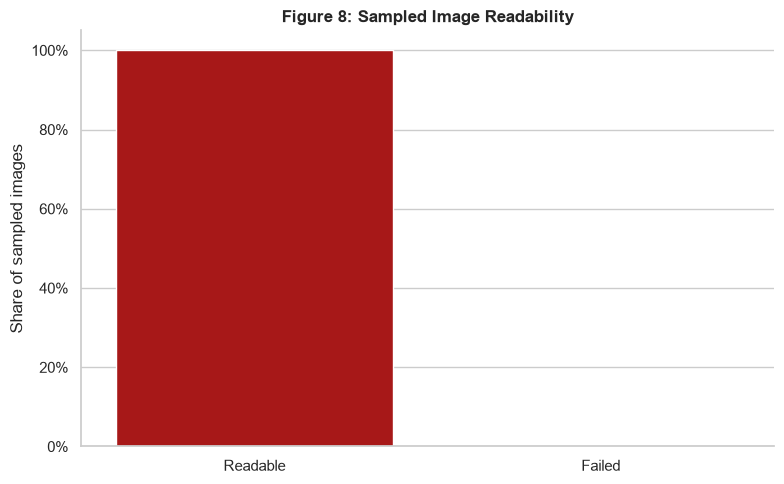

,width,height,aspect_ratio
median,500.0,500.0,1.0
min,500.0,500.0,1.0
max,500.0,500.0,1.0


In [23]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=coverage_plot,
    x="metric",
    y="rate",
    palette=[
        PALETTE["primary"],
        PALETTE["neutral"],
    ],
)

ax.set_ylim(
    0,
    1.05,
)

ax.set_xlabel("")
ax.set_ylabel(
    "Share of sampled images"
)

ax.yaxis.set_major_formatter(
    lambda value, _: f"{value:.0%}"
)

ax.set_title(
    "Figure 8: Sampled Image Readability"
)

plt.tight_layout()
plt.show()

if not image_audit.empty:
    display(
        image_audit.agg({
            "width": [
                "median",
                "min",
                "max",
            ],
            "height": [
                "median",
                "min",
                "max",
            ],
            "aspect_ratio": [
                "median",
                "min",
                "max",
            ],
        })
    )


## 11. Preprocessing Decisions Supported by Figures 3+

- Keep `has_description` as an explicit feature if validation confirms that it helps.
- Compare designation-only, description-only and combined-text models.
- Use word and character representations for text.
- Be careful with duplicated normalized designations when constructing a validation split.
- Keep image loading centralized through `src.data_utils`.
- Figure 6 requires a project-level test-data loader; all other sections run using the existing `load_merged_data()` workflow.
